# Experiment 4: Hill climbing
Steepest-ascent hill climbing on a 1-D landscape and on eight queens, then random restarts
compared with the independent-trials prediction 1 - (1 - p)^k.

In [1]:
import json, os, random
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'font.size': 10, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.4,
                     'legend.frameon': False, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
R = {}

## 1. The landscape, and where hill climbing stops on it

7 local maxima at x = [0.52 1.47 2.75 5.28 7.65 8.85 9.95] | global at x = 7.65
26.0% of 200 evenly spaced starts climb to the global maximum


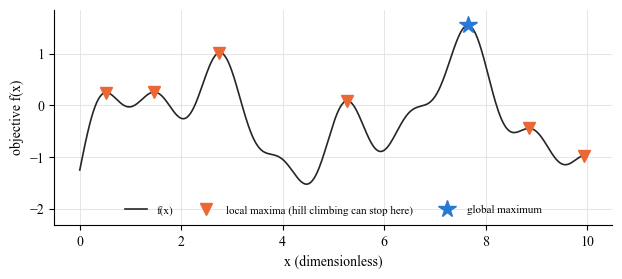

In [2]:
xs = np.linspace(0, 10, 600)
fx = np.sin(xs) + 0.6*np.sin(2.7*xs) + 0.35*np.sin(5.1*xs) - 0.05*(xs - 5)**2
peaks = [i for i in range(1, len(xs) - 1) if fx[i] > fx[i-1] and fx[i] > fx[i+1]]
g = int(np.argmax(fx))

def climb_1d(i):
    """Steepest ascent on the sampled grid: move to the better neighbour until neither is better."""
    while True:
        best = max((j for j in (i-1, i, i+1) if 0 <= j < len(xs)), key=lambda j: fx[j])
        if best == i:
            return i
        i = best

starts = np.arange(0, len(xs), 3)
ends = [climb_1d(int(s)) for s in starts]
share_global = float(np.mean([e == g for e in ends]))
R['landscape'] = dict(n_local_maxima=len(peaks), x_peaks=[float(xs[i]) for i in peaks],
                      f_peaks=[float(fx[i]) for i in peaks], x_global=float(xs[g]), f_global=float(fx[g]),
                      share_starts_reaching_global=share_global, n_starts=len(starts))
print(f'{len(peaks)} local maxima at x =', np.round(xs[peaks], 2), '| global at x =', round(xs[g], 2))
print(f'{100*share_global:.1f}% of {len(starts)} evenly spaced starts climb to the global maximum')

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.plot(xs, fx, color='0.15', lw=1.2, label='f(x)')
loc = [i for i in peaks if i != g]
ax.plot(xs[loc], fx[loc], 'v', color=C[1], ms=8, label='local maxima (hill climbing can stop here)')
ax.plot(xs[g], fx[g], '*', color=C[0], ms=13, label='global maximum')
ax.set_xlabel('x (dimensionless)'); ax.set_ylabel('objective f(x)')
ax.legend(loc='lower center', fontsize=8, ncol=3)
ax.set_ylim(fx.min() - 0.8, fx.max() + 0.3)
fig.savefig('figs/fig4_1_landscape.png'); plt.show()

## 2. Hill climbing on eight queens (minimise conflicts)

In [3]:
def conflicts(board):                       # from Experiment 2
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                bad += 1
    return bad

def hill_climb(n=8, seed=0):
    """Steepest descent on conflicts from a random complete board. Returns (solved, steps, final conflicts)."""
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]
    steps = 0
    while True:
        current = conflicts(board)
        if current == 0:
            return True, steps, 0
        best, move = current, None
        for c in range(n):                  # try every single-queen move within its column
            old = board[c]
            for row in range(n):
                if row == old:
                    continue
                board[c] = row
                v = conflicts(board)
                if v < best:
                    best, move = v, (c, row)
            board[c] = old
        if move is None:
            return False, steps, current    # local minimum (or plateau): stuck
        board[move[0]] = move[1]; steps += 1

def hill_climb_restarts(n=8, restarts=10, seed=0):
    for k in range(restarts):
        if hill_climb(n, seed=seed*1000 + k)[0]:
            return True
    return False

STARTS = 1000
out = [hill_climb(8, seed=s) for s in range(STARTS)]
succ = sum(o[0] for o in out); p = succ / STARTS
stuck_h = [o[2] for o in out if not o[0]]
R['plain'] = dict(starts=STARTS, successes=succ, p=p,
                  mean_steps_success=float(np.mean([o[1] for o in out if o[0]])),
                  mean_steps_fail=float(np.mean([o[1] for o in out if not o[0]])),
                  mean_conflicts_when_stuck=float(np.mean(stuck_h)))
print(f'plain hill climbing: {succ}/{STARTS} = {100*p:.1f}%')
print(f"steps when solved {R['plain']['mean_steps_success']:.2f}, when stuck {R['plain']['mean_steps_fail']:.2f}, "
      f"conflicts left when stuck {R['plain']['mean_conflicts_when_stuck']:.2f}")

# the same estimate from five independent batches of 200 starts: how much does p move?
batches = []
for b in range(5):
    k = sum(hill_climb(8, seed=10_000 + 200*b + s)[0] for s in range(200))
    batches.append(k / 200)
R['batches_200'] = batches
print('five batches of 200 starts:', [f'{100*x:.1f}%' for x in batches],
      f'| binomial s.e. at n = 200: {100*np.sqrt(p*(1-p)/200):.1f} points')

plain hill climbing: 133/1000 = 13.3%
steps when solved 4.23, when stuck 3.07, conflicts left when stuck 1.44


five batches of 200 starts: ['16.0%', '17.0%', '8.5%', '14.0%', '15.0%'] | binomial s.e. at n = 200: 2.4 points


## 3. Random restarts against the prediction 1 - (1 - p)^k

k =  1: measured  15.2% of 500, predicted  13.3%


k =  2: measured  25.8% of 500, predicted  24.8%


k =  5: measured  56.2% of 500, predicted  51.0%


k = 10: measured  81.4% of 500, predicted  76.0%


k = 20: measured  97.4% of 500, predicted  94.2%
restarts needed for 99% with p = 0.133: 32.3


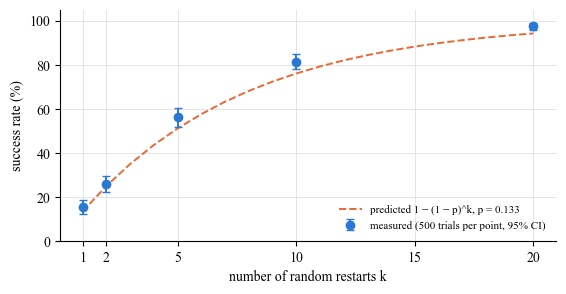

In [4]:
TRIALS = 500
rows = []
for k in (1, 2, 5, 10, 20):
    ok = sum(hill_climb_restarts(8, k, seed=1000 + s) for s in range(TRIALS)) / TRIALS
    pred = 1 - (1 - p)**k
    se = np.sqrt(ok*(1 - ok)/TRIALS)
    rows.append(dict(k=k, trials=TRIALS, measured=ok, predicted=pred, se=float(se)))
    print(f'k = {k:>2}: measured {100*ok:5.1f}% of {TRIALS}, predicted {100*pred:5.1f}%')
R['restarts'] = rows
R['k_for_99'] = float(np.log(0.01) / np.log(1 - p))
print(f"restarts needed for 99% with p = {p:.3f}: {R['k_for_99']:.1f}")

ks = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(ks, 100*(1 - (1 - p)**ks), color=C[1], ls='--', label=f'predicted 1 − (1 − p)^k, p = {p:.3f}')
ax.errorbar([r['k'] for r in rows], [100*r['measured'] for r in rows], yerr=[196*r['se'] for r in rows],
            fmt='o', color=C[0], ms=6, capsize=3, label=f'measured ({TRIALS} trials per point, 95% CI)')
ax.set_xlabel('number of random restarts k'); ax.set_ylabel('success rate (%)')
ax.set_ylim(0, 105); ax.set_xticks([1, 2, 5, 10, 15, 20])
ax.legend(loc='lower right', fontsize=8)
fig.savefig('figs/fig4_2_restarts.png'); plt.show()

In [5]:
with open('results.json', 'w') as fh:
    json.dump(R, fh, indent=1)
print('saved results.json')

saved results.json
